# 17 実測と気象の前処理

## 目的
測定整理・BEMS・湿り空気計算に共通する、時刻、欠測、単位と物性変換を確認します。元データを読む前に合成データで処理を確認します。APIサーバーは不要です。

原典の測定データ取得や外部サービスへの書込みは実行していません。センサーごとの欠測補間、集計区間、計測時刻の意味は、原典で確認します。日射入力では1時間平均か瞬時値か、区間の先頭／末尾かをそろえます。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/17/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import matplotlib.pyplot as plt
import japanize_matplotlib


In [3]:
import numpy as np
import pandas as pd
from vtsimnx.archenv.archenv import (
    humidity_ratio_from_rh, relative_humidity_from_humidity_ratio,
    total_enthalpy_kjkg,
)

# 物性の単位：t[℃], RH[%], x[kg/kg(DA)], h[kJ/kg(DA)]
t, rh = 26.0, 60.0
x = float(humidity_ratio_from_rh(t, rh))
h = float(total_enthalpy_kjkg(t, rh))
assert abs(float(relative_humidity_from_humidity_ratio(t, x))-rh) < 1e-10
assert abs(x-0.012628500507607793) < 1e-9
print({"t_degC": t, "RH_pct": rh, "x_kgkg": x, "x_gkg": 1000*x, "h_kJkg": h})

# 模擬測定データ：重複時刻・欠測を可視化してから整形する。
sample = pd.DataFrame({
    "time": ["2026-08-01 00:00", "2026-08-01 01:00", "2026-08-01 01:00", "2026-08-01 03:00"],
    "temperature": [26., 27., 27.2, 29.], "rh": [60., 65., 63., 70.]})
sample["time"] = pd.to_datetime(sample["time"])
print("重複時刻数", int(sample["time"].duplicated().sum()))
hourly = sample.groupby("time").mean().asfreq("h")
hourly["missing"] = hourly["temperature"].isna()
print(hourly)
# ここでは欠測を残す。補間・削除は、センサーと目的に応じて別途決める。
hourly["x_kgkg"] = humidity_ratio_from_rh(hourly.temperature, hourly.rh)
assert len(hourly) == 4 and int(hourly["missing"].sum()) == 1


{'t_degC': 26.0, 'RH_pct': 60.0, 'x_kgkg': 0.012628500507607793, 'x_gkg': 12.628500507607793, 'h_kJkg': 58.32126012994099}
重複時刻数 1
                     temperature    rh  missing
time                                           
2026-08-01 00:00:00         26.0  60.0    False
2026-08-01 01:00:00         27.1  64.0    False
2026-08-01 02:00:00          NaN   NaN     True
2026-08-01 03:00:00         29.0  70.0    False


## 面日射への変換
南向き・鉛直面を例に、GHIから直散分離した面日射を求めます。この例は日本標準時のタイムゾーン情報を持たない時刻列です。海外データやUTCの計測値は、この設定へそのまま渡しません。


<Axes: title={'center': 'Synthetic solar input'}, ylabel='W/m²'>

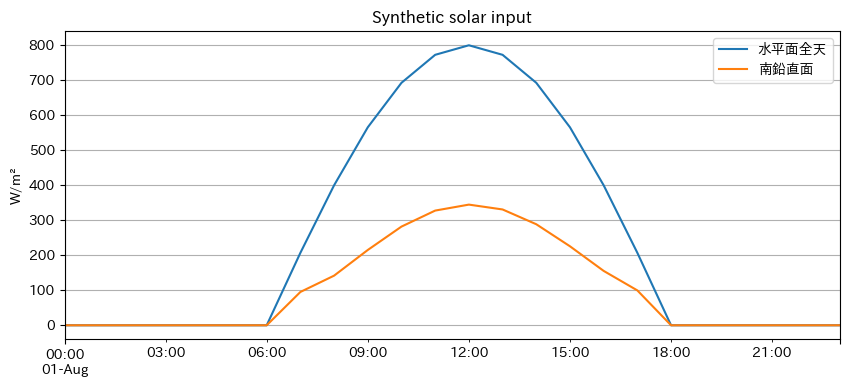

In [4]:
import vtsimnx as vt
idx = pd.date_range("2026-08-01", periods=24, freq="h")
# 教材用の合成水平面全天日射量。実際の気象データではない。
ghi = pd.Series(800*np.maximum(np.sin(np.pi*(idx.hour-6)/12),0), index=idx, name="GHI")
south = vt.solar_gain_by_angles(azimuth_deg=0, tilt_deg=90,
    lat_deg=34.8, lon_deg=135.5, ghi=ghi)
assert np.isfinite(south).all() and (south >= 0).all()
assert south[ghi == 0].max() < 1e-9
pd.DataFrame({"水平面全天":ghi, "南鉛直面":south}).plot(
    figsize=(10,4), grid=True, ylabel="W/m²", title="Synthetic solar input")


## 発展
1. 実測CSVを読み、重複時刻・欠測数・タイムゾーン・列単位を記録する。
2. RHの単純平均から計算する絶対湿度と、各時刻の絶対湿度を平均した値を比較する。
3. 建物側の境界条件と測定値の時間区間をそろえる。

関連原典は、管理者のDrive調査台帳の13・17・18・19分野（測定・BEMS・物性関連）です。冷媒R32の線図は別物性系（CoolProp等）であり、湿り空気の式で代替しません。